# NVDA 2026Q2 earnings options backtest

Replay the August 26, 2026 after-close earnings event with the reusable `Backtest` engine. Compare upside- and downside-target short straddles, a bullish risk reversal, and call butterflies centered on both implied-move targets. The notebook uses the repository's research label **2026Q2**.

This is a single-event worked example. Quotes, expirations, and entry times within this event are related observations. P&L is in USD per structure and includes simulated bid/ask execution. The default additional fee is zero, and financing, stock borrow, and additional slippage are excluded.

## 1. Set the event and execution policy

Enter at the minute stamped 15:30 or 15:45 ET on T-1 or T. Exit on T+1 at the first shared minute with executable quotes for every original leg, starting at 09:31 ET and ending at 10:00 ET. Here the event boundary is immediately after the T regular close. The calendar also determines actual market closes and the 31-calendar-day expiry cutoff.

Set `DELTA_HEDGE = False` to run the options alone. Set it to `True` to also simulate a stock hedge on the same option fills. The output always includes unhedged P&L. With hedging enabled, stock trades rebalance the aggregate bid-mark Black?76 delta to the nearest whole share when all leg quotes support a valid delta. The last pre-event hedge is carried through the gap and liquidated with the options. A hedge failure leaves the unhedged result available.

In [1]:
from io import BytesIO
from pathlib import Path
from runpy import run_path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandas_market_calendars as mcal
from IPython.display import Image, display

from backtest import Backtest, Strategy, VOL_FACTORS
from earnings_event import event_sessions
import helper as h

ROOT = Path.cwd()
DATA_DIR = ROOT / "data" / "raw"
Surfaces = run_path(str(ROOT / "event-backtest.py"))["Surfaces"]

TICKER, EVENT_DATE = "NVDA", "2026-08-26"
ZONE = "America/New_York"
ENTRY_MINUTES = (30, 15)
MAX_DTE = 31
RATE, OFF_HOUR_WEIGHT, MULTIPLIER = 0.04, 0.4, 100
DELTA_HEDGE = True
FEES = 0.0
plt.style.use("seaborn-v0_8-whitegrid")


def show_figure(figure):
    # Embed a PNG even when the backtest CLI has selected the Agg backend.
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
        display(Image(data=buffer.getvalue()))
    plt.close(figure)

## 2. Read and join the quote tables

Each session supplies three local DBN inputs. OPRA CBBO supplies option bid/ask prices and sizes, OPRA definitions supply the expiry and strike, and EQUS BBO supplies the stock quote.

`helper.merge_data()` converts timestamps to UTC and uses two backward as-of joins:

1. Join option quotes to contract definitions by `instrument_id`, using the latest definition with `definition_time <= ts_recv`.
2. Join each option quote to the latest equity quote with `spot_time <= ts_recv` and at most a one-minute lag. The result includes bid, ask, midpoint and quote age. The engine requires the stock and option timestamps to match exactly for execution. The IV-surface fit uses the merged data and permits the one-minute join tolerance.

The following cell shows the join match counts before the engine applies execution filters. Downloaded inputs are required to re-run the notebook.

In [2]:
(dates, closes) = event_sessions({EVENT_DATE: EVENT_DATE})[EVENT_DATE]
prior, event, following = dates
windows = [(prior, "close"), (event, "close"), (following, "open")]
joined_by_day, audit = {}, []
for day, window in windows:
    options, definitions, equity = h.load_data(day, TICKER, DATA_DIR, window=window)
    joined = h.merge_data(options, definitions, equity)
    joined_by_day[day] = joined
    audit.append({
        "session": day, "window": window, "option rows": len(options),
        "definition rows": len(definitions), "equity rows": len(equity),
        "matched definition": joined.definition_time.notna().sum(),
        "matched stock": joined.spot_time.notna().sum(),
        "same-minute stock": joined.ts_recv.eq(joined.spot_time).sum(),
    })

quotes = pd.concat(joined_by_day.values(), ignore_index=True)
display(pd.DataFrame(audit))

schedule = mcal.get_calendar("NYSE").schedule(
    start_date=prior, end_date=quotes.expiration.max().date(),
)
market_open = schedule.at[pd.Timestamp(following), "market_open"]
exit_start = market_open + pd.Timedelta(minutes=1)
exit_end = market_open + pd.Timedelta(minutes=30)
event_time = closes.iloc[1] + pd.Timedelta(1, unit="ns")
surfaces = Surfaces(quotes, schedule)
engine = Backtest(
    quotes, schedule, surface=surfaces.components, rate=RATE,
    off_hour_weight=OFF_HOUR_WEIGHT, multiplier=MULTIPLIER,
)

,session,window,option rows,definition rows,equity rows,matched definition,matched stock,same-minute stock
0,2026-08-25,close,101178,3440,30,101178,101178,101178
1,2026-08-26,close,103334,3504,30,103334,103334,103334
2,2026-08-27,open,104779,3566,30,104779,104779,104779


## 3. Estimate the implied move and select strikes

At each entry timestamp, the surface estimator fits a weighted quadratic to OTM mid IV by expiry. It derives the forward from call/put parity. With $k=\log(K/F)$, the curve is $\widehat\sigma(k)=a+bk+ck^2$. The entry-time OLS fits $a^2\tau=\alpha+\beta\tau$ across eligible expiries that span the announcement. The move is $m=\sqrt{\alpha}$ when $\alpha\geq0$. Given the synchronized stock bid $S$, the targets are $S e^{-m}$ and $S e^{m}$.

| Strategy | Entry selection for each eligible expiry |
| --- | --- |
| Upside / downside short straddle | Sell one call and one put at the **same strike** nearest the upper / lower target, among pairs with executable bids. |
| Bullish risk reversal | Buy one call nearest the upper target with executable ask size. Sell one put nearest the lower target with executable bid size. The put strike must be below the call strike. |
| Upside / downside call butterfly | Buy one lower call, sell **two** center calls, and buy one upper call at the same expiry. Wings must be symmetric in strike around the middle. Rank candidates first by the center's absolute distance to the target, then by the wing width's absolute distance to $K_{\rm target}\sinh(m)$, then by ascending strikes. The center bid must support two contracts. |

For straddles and risk reversals, ties in distance use the lower strike. Position selection uses only the entry snapshot. Entries buy at ask and sell at bid, and exits reverse those sides. The entry diagnostics below show stock bid and a fitted ATM IV reference at the **earliest priced common expiry**. The next table shows the actual strikes and per-leg entry fill IVs.

In [3]:
strategies = [
    Strategy("straddle", "short", "up"),
    Strategy("straddle", "short", "down"),
    Strategy("risk_reversal", "bullish"),
    Strategy("butterfly", "long", "up"),
    Strategy("butterfly", "long", "down"),
]
labels = {
    "up_short_straddle": "Upside short straddle",
    "down_short_straddle": "Downside short straddle",
    "bullish_risk_reversal": "Bullish risk reversal",
    "up_long_butterfly": "Upside call butterfly",
    "down_long_butterfly": "Downside call butterfly",
}
trade_parts, leg_parts = [], []
for phase, close in zip(("T-1", "T"), closes.iloc[:2], strict=True):
    for minutes in ENTRY_MINUTES:
        entry = close - pd.Timedelta(minutes=minutes)
        move = surfaces.event_move(entry, event_time, MAX_DTE)
        label = f"{phase} {entry.tz_convert(ZONE):%H:%M}"
        for strategy in strategies:
            result = engine.run(
                strategy, entry=entry, exit_start=exit_start, exit_end=exit_end,
                event_time=event_time, implied_move=move, max_dte=MAX_DTE,
                delta_hedge=DELTA_HEDGE, fees=FEES,
            )
            trade_parts.append(result.trades.assign(entry_label=label))
            leg_parts.append(result.legs.assign(entry_label=label))

trades = pd.concat(trade_parts, ignore_index=True)
legs = pd.concat(leg_parts, ignore_index=True)
priced = trades.loc[trades.status.eq("priced")].copy()
strategies_order = list(labels)
entry_order = priced.sort_values("entry_time").entry_label.unique()
common = priced.groupby("expiration").size()
reference_expiry = common.loc[common.eq(len(strategies) * len(entry_order))].index.min()

entries = priced.loc[priced.expiration.eq(reference_expiry)].drop_duplicates("entry_time").copy()
entries = entries.sort_values("entry_time")
entries["ATM reference IV"] = [
    surfaces.fit(t, reference_expiry).atm_iv_quadratic for t in entries.entry_time
]
entries["Lower strike target"] = entries.entry_stock_bid * np.exp(-entries.implied_move)
entries["Upper strike target"] = entries.entry_stock_bid * np.exp(entries.implied_move)
entry_table = entries.set_index("entry_label").rename(columns={
    "entry_stock_bid": "Entry stock bid", "implied_move": "Implied move",
})
print(f"Common reference expiry: {reference_expiry:%Y-%m-%d}")
display(entry_table[[
    "Entry stock bid", "ATM reference IV", "Implied move", "Lower strike target", "Upper strike target",
]].style.format({
    "Entry stock bid": "${:.2f}", "ATM reference IV": "{:.2%}", "Implied move": "{:.2%}",
    "Lower strike target": "${:.2f}", "Upper strike target": "${:.2f}",
}))

Common reference expiry: 2026-08-28


,Entry stock bid,ATM reference IV,Implied move,Lower strike target,Upper strike target
entry_label,,,,,
T-1 15:30,$212.00,77.69%,6.55%,$198.56,$226.35
T-1 15:45,$212.44,77.69%,6.56%,$198.96,$226.83
T 15:30,$210.89,93.46%,6.71%,$197.20,$225.53
T 15:45,$209.59,93.35%,6.70%,$196.01,$224.11


### Entry IV of each traded leg

The table recomputes IV from the **actual entry fill** with the engine's stock-bid forward $F=S_{\rm bid}/D$, the engine's discount $D$, and its variance clock $\tau$. A buy therefore uses the ask and a sell uses the bid. This fill IV is distinct from both the fitted ATM reference IV and the bid-side mark used for attribution. A fill with no IV solution under those assumptions is shown as unavailable.

In [4]:
def entry_fill_iv(row):
    expiry_close = schedule.at[row.expiration.tz_localize(None), "market_close"]
    _, _, calendar_time, variance_time = h.calculate_variance_time(
        row.entry_time, expiry_close, schedule, OFF_HOUR_WEIGHT,
    )
    discount = np.exp(-RATE * calendar_time)
    return h.implied_vol(
        row.entry_fill, row.entry_stock_bid / discount, row.strike,
        discount, variance_time, row.side,
    )

keys = ["entry_time", "expiration", "strategy"]
priced["Realized move"] = np.log(priced.exit_stock_bid / priced.entry_stock_bid)
legs = legs.merge(
    priced[keys + ["entry_stock_bid"]], on=keys, how="left", validate="many_to_one",
)
legs["Entry fill IV"] = [entry_fill_iv(row) for row in legs.itertuples(index=False)]
reference_legs = legs.loc[legs.expiration.eq(reference_expiry)].copy()
reference_legs["Signed leg"] = [
    f"{q:+d} {side} {strike:g}" for q, side, strike in
    zip(reference_legs.quantity, reference_legs.side, reference_legs.strike, strict=True)
]
reference_legs["Strike and IV"] = [
    f"{leg} @ {iv:.1%}" if np.isfinite(iv) else f"{leg} @ unavailable"
    for leg, iv in zip(reference_legs["Signed leg"], reference_legs["Entry fill IV"], strict=True)
]
leg_table = reference_legs.groupby(["entry_label", "strategy"])["Strike and IV"].agg(" / ".join)
display(leg_table.unstack().reindex(index=entry_order, columns=strategies_order).rename(columns=labels))

strategy,Upside short straddle,Downside short straddle,Bullish risk reversal,Upside call butterfly,Downside call butterfly
entry_label,,,,,
T-1 15:30,-1 C 227.5 @ 81.1% / -1 P 227.5 @ 79.0%,-1 C 197.5 @ 77.0% / -1 P 197.5 @ 75.7%,+1 C 227.5 @ 81.5% / -1 P 197.5 @ 75.7%,+1 C 212.5 @ 78.6% / -2 C 227.5 @ 81.1% / +1 C...,+1 C 185 @ 93.6% / -2 C 197.5 @ 77.0% / +1 C 2...
T-1 15:45,-1 C 227.5 @ 80.7% / -1 P 227.5 @ 79.4%,-1 C 200 @ 76.3% / -1 P 200 @ 76.0%,+1 C 227.5 @ 81.1% / -1 P 200 @ 76.0%,+1 C 212.5 @ 78.6% / -2 C 227.5 @ 80.7% / +1 C...,+1 C 187.5 @ 91.8% / -2 C 200 @ 76.3% / +1 C 2...
T 15:30,-1 C 225 @ 96.6% / -1 P 225 @ 95.3%,-1 C 197.5 @ 91.5% / -1 P 197.5 @ 91.6%,+1 C 225 @ 96.8% / -1 P 197.5 @ 91.6%,+1 C 210 @ 94.7% / -2 C 225 @ 96.6% / +1 C 240...,+1 C 185 @ 107.2% / -2 C 197.5 @ 91.5% / +1 C ...
T 15:45,-1 C 225 @ 96.7% / -1 P 225 @ 94.6%,-1 C 195 @ 91.5% / -1 P 195 @ 91.3%,+1 C 225 @ 97.2% / -1 P 195 @ 91.3%,+1 C 210 @ 95.5% / -2 C 225 @ 96.7% / +1 C 240...,+1 C 180 @ 121.7% / -2 C 195 @ 91.5% / +1 C 21...


## 4. Reconcile P&L and attribute it to Greeks

For leg $j$ with signed quantity $q_j$ and contract multiplier $M$, its executed P&L is $q_j M(P_{\rm exit\ fill}-P_{\rm entry\ fill})$. Let $V(S,C,\sigma)$ be its Black?76 price per share at spot bid $S$, clock $C=(D,\tau)$, and IV $\sigma$. For two consecutive model marks with bid-side IVs $\sigma_0,\sigma_1$, attribute the following per share before multiplying by $q_jM$:

$$
\begin{aligned}
\mathrm{Delta}&=\Delta_0(S_1-S_0),\\
\mathrm{Gamma}&=V(S_1,C_0,\sigma_0)-V(S_0,C_0,\sigma_0)-\mathrm{Delta},\\
\mathrm{Theta}&=V(S_1,C_1,\sigma_0)-V(S_1,C_0,\sigma_0),\\
\mathrm{Vega}&=V(S_1,C_1,\sigma_1)-V(S_1,C_1,\sigma_0).
\end{aligned}
$$

Here $\Delta_0=\phi\,\Phi(\phi d_1)$, with $\phi=+1$ for calls and $-1$ for puts, $F_0=S_0/D_0$, and $d_1=\log(F_0/K)/(\sigma_0\sqrt{\tau_0})+\tfrac12\sigma_0\sqrt{\tau_0}$ for positive IV. At zero IV the engine uses the intrinsic-value delta limit. Gamma includes higher-order spot effects. The execution and model basis is the difference between fill P&L and summed model-mark changes. It includes crossing the spread and any bid-mark clipping to the model range. Net hedged P&L is option P&L plus stock cash flow minus fees. Unhedged P&L omits stock cash flow. The earnings-gap columns isolate the quote interval that crosses the event boundary.

### Vega decomposition

At each endpoint set $k_i=\log(K/F_i)$ using that endpoint's fitted surface forward. Define $\epsilon_i=\sigma_i-(a_i+b_i k_i+c_i k_i^2)$. The four changes in IV are

$$
(\delta_A,\delta_B,\delta_C,\delta_R)
=(a_1-a_0,\ b_1k_1-b_0k_0,\ c_1k_1^2-c_0k_0^2,\ \epsilon_1-\epsilon_0).
$$

Starting from $s_0=\sigma_0$, add each change in order, $s_j=s_{j-1}+\delta_j$. Component $j$ contributes $q M[V(S_1,C_1,s_j)-V(S_1,C_1,s_{j-1})]$. The four differences telescope to Vega. Skew and smile include the contract's move along the surface as $k$ changes. Component values depend on the repricing order. Missing surface estimates or negative intermediate IVs leave those components unavailable while preserving total Vega.

In [5]:
factors = ["delta_usd", "gamma_usd", "theta_usd", "vega_usd"]
attributed = priced.loc[priced.attribution_status.eq("attributed")]
np.testing.assert_allclose(
    attributed[factors].sum(axis=1) + attributed.option_execution_and_model_basis_usd,
    attributed.option_pnl_usd, atol=1e-7, rtol=0,
)
coverage = []
for prefix, label in (("", "Full holding period"), ("earnings_gap_", "Earnings gap")):
    columns = [f"{prefix}{name}_usd" for name in VOL_FACTORS]
    available = attributed.dropna(subset=columns)
    np.testing.assert_allclose(
        available[columns].sum(axis=1), available[f"{prefix}vega_usd"], atol=1e-7, rtol=0,
    )
    coverage.append({"period": label, "available breakdowns": len(available), "priced trades": len(priced)})

print(f"{len(priced)} of {len(trades)} setups priced. {len(attributed)} option attributions reconciled.")
if DELTA_HEDGE:
    hedge_ok = priced.loc[priced.hedge_status.eq("priced")]
    np.testing.assert_allclose(
        hedge_ok.unhedged_pnl_usd + hedge_ok.stock_pnl_usd,
        hedge_ok.hedged_pnl_usd, atol=1e-7, rtol=0,
    )
    display(priced.groupby("hedge_status").size().rename("Trades").to_frame())
display(pd.DataFrame(coverage))

150 of 150 setups priced. 150 option attributions reconciled.


,Trades
hedge_status,
Cannot infer entry bid-side delta,6
priced,144


,period,available breakdowns,priced trades
0,Full holding period,132,150
1,Earnings gap,143,150


## 5. Compare P&L across entry times

The first chart averages results over eligible expiries within each entry time and strategy. The hedged panel uses priced hedges only. The table below reports both denominators. Compare P&L with the entry stock bid and fitted ATM IV printed on each column group. Those IV labels use the common reference expiry described above.

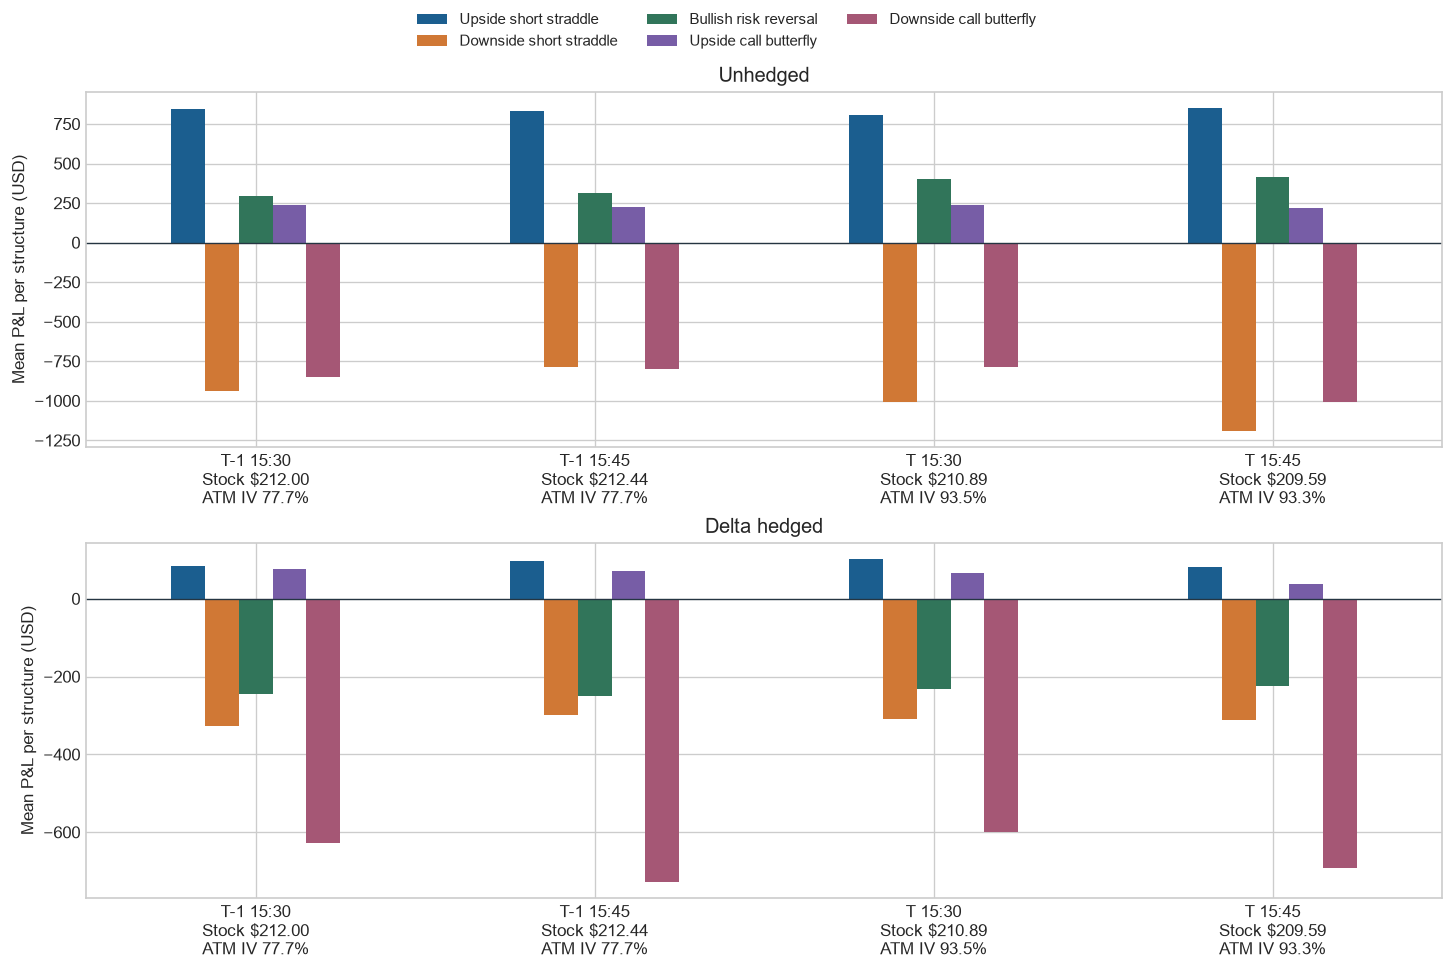

In [6]:
plot_labels = [
    f"{entry}\nStock ${entry_table.at[entry, 'Entry stock bid']:.2f}\nATM IV {entry_table.at[entry, 'ATM reference IV']:.1%}"
    for entry in entry_order
]
pnl_views = [("unhedged_pnl_usd", "Unhedged")]
if DELTA_HEDGE:
    pnl_views.append(("hedged_pnl_usd", "Delta hedged"))
fig, axes = plt.subplots(len(pnl_views), 1, figsize=(12, 4 * len(pnl_views)),
                         squeeze=False, layout="constrained")
colors = ["#1b5e8f", "#d07835", "#31755a", "#775da6", "#a55775"]
for ax, (field, title) in zip(axes.flat, pnl_views, strict=True):
    values = priced.pivot_table(index="entry_label", columns="strategy", values=field)
    values = values.reindex(index=entry_order, columns=strategies_order).rename(columns=labels)
    values.plot.bar(ax=ax, color=colors, rot=0, legend=False)
    ax.set_xticklabels(plot_labels, rotation=0)
    ax.axhline(0, color="#253542", linewidth=.8)
    ax.set(title=title, ylabel="Mean P&L per structure (USD)", xlabel="")
handles, chart_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, chart_labels, ncols=3, loc="outside upper center", fontsize=9)
show_figure(fig)

aggregations = {"Unhedged N": ("unhedged_pnl_usd", "count"),
                "Unhedged mean": ("unhedged_pnl_usd", "mean")}
if DELTA_HEDGE:
    aggregations.update({"Hedged N": ("hedged_pnl_usd", "count"),
                         "Hedged mean": ("hedged_pnl_usd", "mean")})
summary = priced.assign(Strategy=priced.strategy.map(labels)).groupby(
    ["entry_label", "Strategy"], sort=False,
).agg(**aggregations)
display(summary.style.format({c: "{:+,.2f}" for c in summary if c.endswith("mean")},
                             na_rep="Unavailable"))

### P&L by expiry and earnings-gap factors

Each line shows one entry time across expirations. The final chart compares mean earnings-gap attribution by strategy. Each Vega subcomponent uses only trades with a complete four-part gap decomposition, so the four bars can be interpreted on the same sample within each strategy.

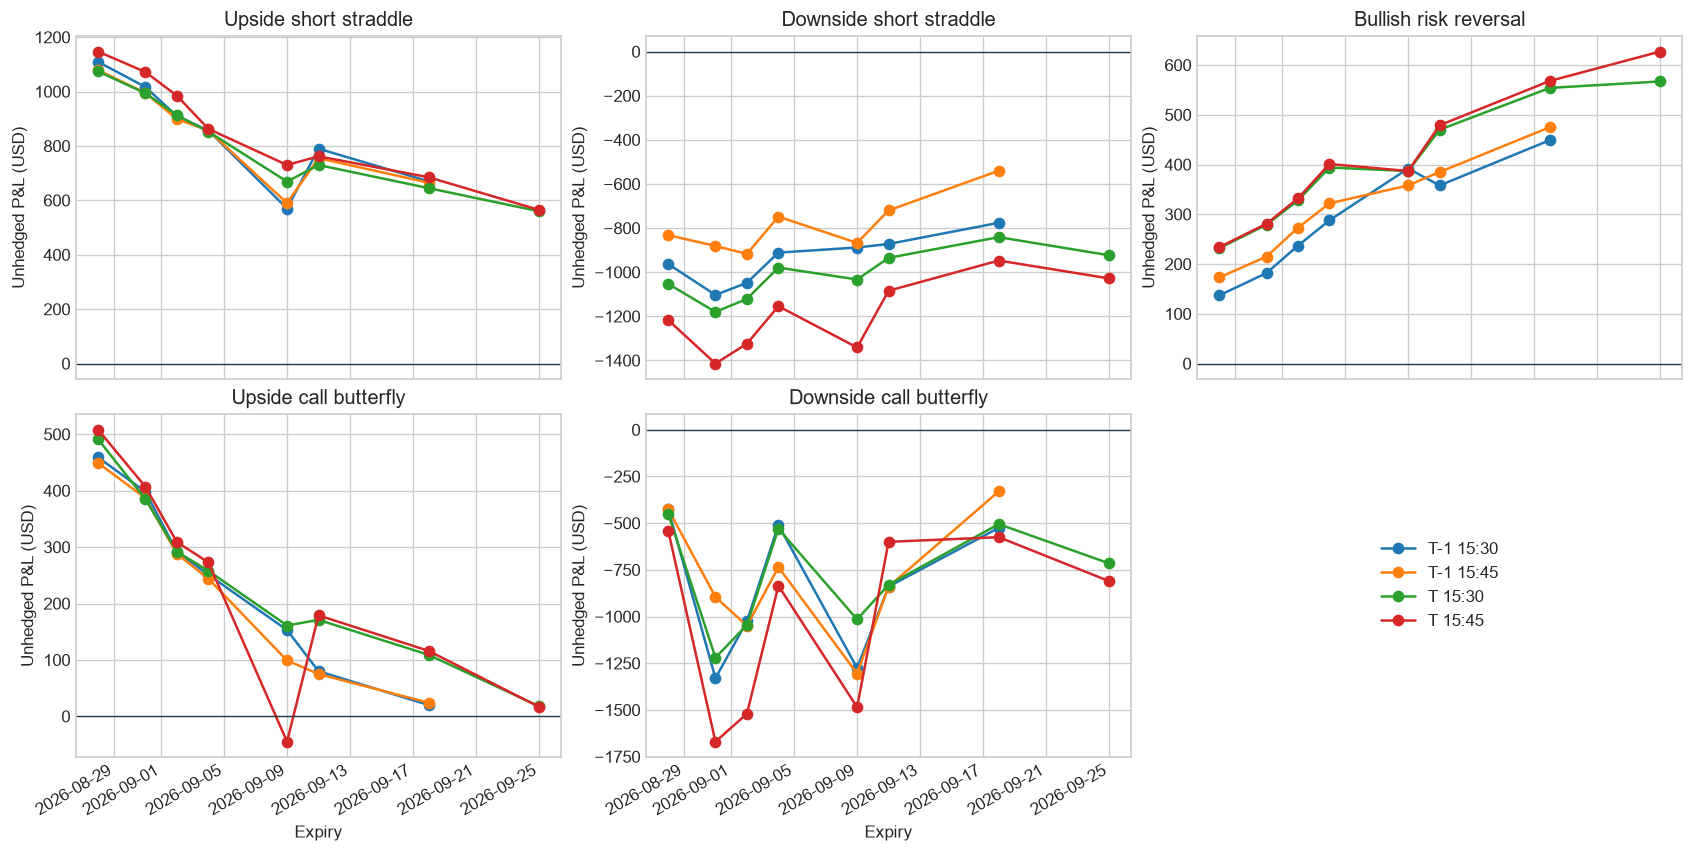

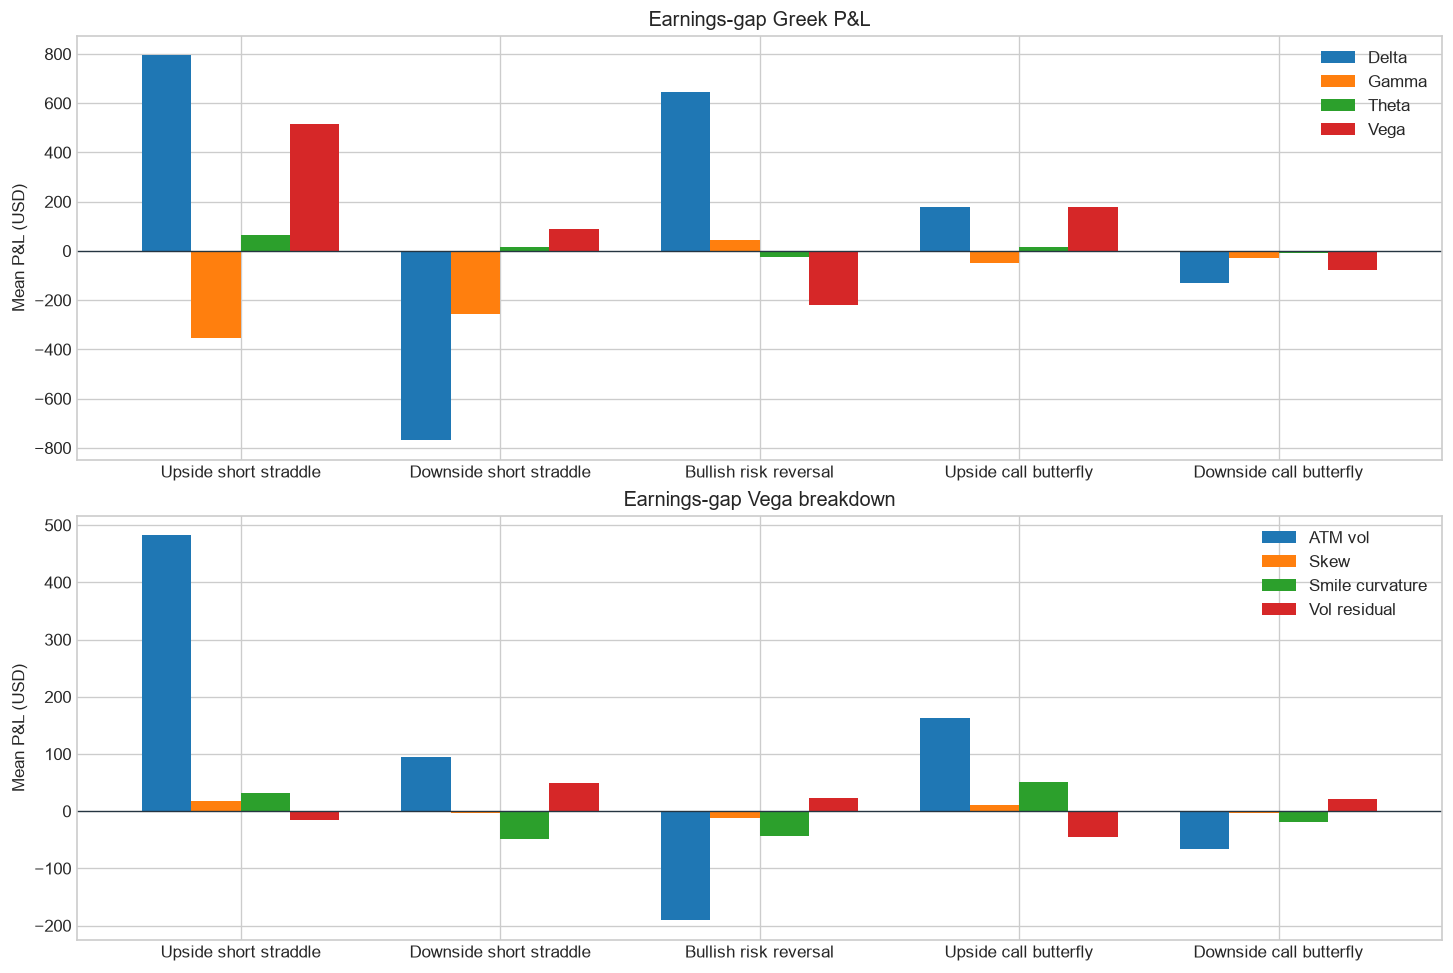

Complete gap Vega breakdowns by strategy


,Trades
strategy,
Upside short straddle,30
Downside short straddle,30
Bullish risk reversal,30
Upside call butterfly,30
Downside call butterfly,23


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, layout="constrained")
for ax, strategy in zip(axes.flat, strategies_order):
    frame = priced.loc[priced.strategy.eq(strategy)].pivot(
        index="expiration", columns="entry_label", values="unhedged_pnl_usd",
    ).reindex(columns=entry_order)
    frame.plot(ax=ax, marker="o", legend=False)
    ax.axhline(0, color="#253542", linewidth=.8)
    ax.set(title=labels[strategy], xlabel="Expiry", ylabel="Unhedged P&L (USD)")
axes.flat[-1].axis("off")
handles, chart_labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, chart_labels, loc="center")
show_figure(fig)

greek_columns = [f"earnings_gap_{factor}_usd" for factor in ("delta", "gamma", "theta", "vega")]
vol_columns = [f"earnings_gap_{factor}_usd" for factor in VOL_FACTORS]
gap_pnl = priced.groupby("strategy")[greek_columns].mean().reindex(strategies_order)
vol_available = priced.dropna(subset=vol_columns)
vol_pnl = vol_available.groupby("strategy")[vol_columns].mean().reindex(strategies_order)
gap_pnl.columns = ["Delta", "Gamma", "Theta", "Vega"]
vol_pnl.columns = ["ATM vol", "Skew", "Smile curvature", "Vol residual"]
fig, axes = plt.subplots(2, 1, figsize=(12, 8), layout="constrained")
for ax, data, title in [
    (axes[0], gap_pnl, "Earnings-gap Greek P&L"),
    (axes[1], vol_pnl, "Earnings-gap Vega breakdown"),
]:
    data.rename(index=labels).plot.bar(ax=ax, rot=0, width=.76)
    ax.axhline(0, color="#253542", linewidth=.8)
    ax.set(title=title, ylabel="Mean P&L (USD)", xlabel="")
show_figure(fig)
print("Complete gap Vega breakdowns by strategy")
display(vol_available.groupby("strategy").size().reindex(strategies_order, fill_value=0)
        .rename(index=labels).rename("Trades").to_frame())